# 06 — Key Signal Identification

## Objective

This notebook identifies anonymous measurement signals that contribute
to Fail-risk prediction.

The objectives are:

1. estimate feature importance using validation-fold permutation
   importance;
2. examine whether important features remain stable across
   cross-validation folds;
3. compare predictive importance with statistical feature-selection
   evidence;
4. examine the direction of association between selected signals and
   Fail risk;
5. produce a short list of anonymous signals for engineering
   investigation.

The identified variables are anonymous predictive signals. Their
importance does not establish physical causality or identify a specific
tool, chamber, or process parameter.

## 6.1 Method Selection

Random Forest is used as the primary model for signal identification
because it provided a strong threshold trade-off in the previous
chapter and can represent nonlinear relationships and interactions.

Permutation importance measures how much validation performance
decreases when one feature is randomly shuffled.

The logic is:

- if shuffling a feature causes a large decrease in Average Precision,
  the model relied on that feature;
- if shuffling a feature has little effect, the feature contributed
  little additional predictive information;
- if importance is consistently positive across folds, the signal is
  more stable than a feature that appears important in only one fold.

Permutation importance is calculated on validation folds rather than
on the training data. This reduces the risk of reporting importance
that only reflects training-set overfitting.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline

## 6.2 Load and Validate the Data

The original measurement and label files are loaded again so that this
notebook can be executed independently.

The original `-1/+1` labels are converted to:

- `0`: Pass;
- `1`: Fail.

In [3]:
data_dir = Path("../data/raw")

feature_path = data_dir / "secom.data"
label_path = data_dir / "secom_labels.data"

X = pd.read_csv(
    feature_path,
    sep=r"\s+",
    header=None
)

X.columns = [
    f"feature_{column_number}"
    for column_number in range(X.shape[1])
]

labels = pd.read_csv(
    label_path,
    sep=r"\s+",
    header=None,
    names=[
        "original_label",
        "timestamp_text"
    ]
)

y = (
    labels["original_label"] == 1
).astype(int)

In [4]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClass counts:")
print(y.value_counts().sort_index())

print(
    "\nMissing measurement values:",
    X.isna().sum().sum()
)

assert len(X) == len(y)
assert set(y.unique()) == {0, 1}

X shape: (1567, 590)
y shape: (1567,)

Class counts:
original_label
0    1463
1     104
Name: count, dtype: int64

Missing measurement values: 41951


## 6.3 Recreate the Cross-Validation Design

The same stratified 10-fold cross-validation design used in the
previous chapters is retained.

This keeps the signal-identification experiment consistent with the
model-evaluation experiment.

In [5]:
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

## 6.4 Recreate the Random Forest Pipeline

The Random Forest configuration is kept consistent with Chapter 5.

The preprocessing steps are fitted separately inside each training
fold:

1. median imputation;
2. removal of constant features;
3. Random Forest training.

Feature scaling is not required for Random Forest.

In [6]:
random_forest_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "remove_constants",
        VarianceThreshold(threshold=0.0)
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=6,
            min_samples_leaf=3,
            max_features="sqrt",
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        )
    )
])

random_forest_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('remove_constants', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimat

## 6.5 Demonstrate Permutation Importance on One Fold

The first cross-validation fold is used to demonstrate the procedure
before importance is aggregated across all ten folds.

In [7]:
train_index, validation_index = next(
    cv.split(X, y)
)

X_train_fold = X.iloc[train_index]
X_validation_fold = X.iloc[validation_index]

y_train_fold = y.iloc[train_index]
y_validation_fold = y.iloc[validation_index]

first_fold_model = clone(
    random_forest_pipeline
)

first_fold_model.fit(
    X_train_fold,
    y_train_fold
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('remove_constants', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](590,)","['feature_0','feature_1','feature_2',...,'feature_587','feature_588', 'feature_589']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,590
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_va

In [8]:
first_fold_scores = (
    first_fold_model.predict_proba(
        X_validation_fold
    )[:, 1]
)

first_fold_ap = average_precision_score(
    y_validation_fold,
    first_fold_scores
)

print(
    "First-fold Average Precision:",
    round(first_fold_ap, 4)
)

First-fold Average Precision: 0.434


In [9]:
first_fold_permutation = permutation_importance(
    estimator=first_fold_model,
    X=X_validation_fold,
    y=y_validation_fold,
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

In [10]:
first_fold_importance = pd.DataFrame({
    "feature": X.columns,
    "importance_mean": (
        first_fold_permutation.importances_mean
    ),
    "importance_std": (
        first_fold_permutation.importances_std
    )
}).sort_values(
    "importance_mean",
    ascending=False
)

first_fold_importance.head(10)

,feature,importance_mean,importance_std
33,feature_33,0.065239,0.029031
341,feature_341,0.065092,0.009883
19,feature_19,0.056813,0.002120
197,feature_197,0.039889,0.025606
63,feature_63,0.035773,0.023806
90,feature_90,0.034946,0.019096
323,feature_323,0.034116,0.024677
334,feature_334,0.031626,0.031642
390,feature_390,0.029755,0.022238
519,feature_519,0.027798,0.015225


## 6.6 Cross-Validated Permutation Importance

Permutation importance is now calculated independently in every
validation fold.

This produces ten importance estimates for each of the 590 anonymous
measurement features.

In [11]:
fold_importance_rows = []
fold_performance_rows = []

for fold_number, (
    train_index,
    validation_index
) in enumerate(
    cv.split(X, y),
    start=1
):

    X_train_fold = X.iloc[train_index]
    X_validation_fold = X.iloc[validation_index]

    y_train_fold = y.iloc[train_index]
    y_validation_fold = y.iloc[validation_index]

    fold_model = clone(
        random_forest_pipeline
    )

    fold_model.fit(
        X_train_fold,
        y_train_fold
    )

    validation_scores = (
        fold_model.predict_proba(
            X_validation_fold
        )[:, 1]
    )

    fold_ap = average_precision_score(
        y_validation_fold,
        validation_scores
    )

    fold_permutation = permutation_importance(
        estimator=fold_model,
        X=X_validation_fold,
        y=y_validation_fold,
        scoring="average_precision",
        n_repeats=3,
        random_state=42 + fold_number,
        n_jobs=-1
    )

    fold_importance = pd.DataFrame({
        "fold": fold_number,
        "feature": X.columns,
        "importance": (
            fold_permutation.importances_mean
        )
    })

    fold_importance_rows.append(
        fold_importance
    )

    fold_performance_rows.append({
        "fold": fold_number,
        "validation_ap": fold_ap,
        "validation_fail_count": (
            y_validation_fold.sum()
        )
    })

    print(
        f"Fold {fold_number}: "
        f"AP = {fold_ap:.4f}"
    )

Fold 1: AP = 0.4340
Fold 2: AP = 0.1105
Fold 3: AP = 0.2892
Fold 4: AP = 0.2786
Fold 5: AP = 0.1909
Fold 6: AP = 0.1628
Fold 7: AP = 0.1812
Fold 8: AP = 0.1523
Fold 9: AP = 0.1968
Fold 10: AP = 0.2462


In [12]:
permutation_importance_by_fold = pd.concat(
    fold_importance_rows,
    ignore_index=True
)

fold_performance = pd.DataFrame(
    fold_performance_rows
)

print(
    "Importance table shape:",
    permutation_importance_by_fold.shape
)

fold_performance

Importance table shape: (5900, 3)


,fold,validation_ap,validation_fail_count
0,1,0.434038,10
1,2,0.110505,10
2,3,0.289188,10
3,4,0.278568,11
4,5,0.190878,11
5,6,0.162771,11
6,7,0.181179,11
7,8,0.152257,10
8,9,0.196835,10
9,10,0.246210,10


## 6.7 Aggregate Importance and Stability

A useful engineering signal should not appear important in only one
fold.

For each feature, the following statistics are calculated:

- mean permutation importance;
- median permutation importance;
- standard deviation across folds;
- number of folds with positive importance;
- positive-fold rate.

In [13]:
permutation_summary = (
    permutation_importance_by_fold
    .groupby("feature")
    .agg(
        mean_importance=(
            "importance",
            "mean"
        ),
        median_importance=(
            "importance",
            "median"
        ),
        importance_std=(
            "importance",
            "std"
        ),
        positive_folds=(
            "importance",
            lambda values: (values > 0).sum()
        )
    )
)

permutation_summary[
    "positive_fold_rate"
] = (
    permutation_summary["positive_folds"]
    / cv.get_n_splits()
)

permutation_summary = (
    permutation_summary
    .sort_values(
        "mean_importance",
        ascending=False
    )
)

permutation_summary.head(20)

,mean_importance,median_importance,importance_std,positive_folds,positive_fold_rate
feature,,,,,
feature_341,0.007987,0.000942,0.024702,6,0.6
feature_102,0.007829,0.002683,0.016241,9,0.9
feature_460,0.006919,0.003503,0.015968,7,0.7
feature_247,0.006293,0.000409,0.019560,5,0.5
feature_563,0.005937,0.001975,0.010954,7,0.7
feature_31,0.005562,0.002700,0.016937,8,0.8
feature_175,0.005388,0.001421,0.015939,7,0.7
feature_519,0.005160,0.000032,0.012380,5,0.5
feature_224,0.005045,0.000387,0.015757,8,0.8


## 6.8 F-test Selection Stability

Permutation importance measures whether the Random Forest relies on a
feature for validation-set risk ranking.

As an independent statistical comparison, the F-test is repeated
inside each training fold. In every fold, the 40 features with the
largest F-statistics are selected.

The analysis records:

- how many folds selected each feature;
- the feature-selection rate across ten folds;
- the mean and median F-statistic.

All imputation, constant-feature removal, standardization, and feature
selection are fitted using the training portion of each fold only.

In [14]:
from sklearn.feature_selection import (
    SelectKBest,
    f_classif
)
from sklearn.preprocessing import StandardScaler

In [15]:
f_test_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "remove_constants",
        VarianceThreshold(threshold=0.0)
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "select_features",
        SelectKBest(
            score_func=f_classif,
            k=40
        )
    )
])

f_test_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('remove_constants', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimat

In [16]:
f_test_rows = []

for fold_number, (
    train_index,
    validation_index
) in enumerate(
    cv.split(X, y),
    start=1
):

    X_train_fold = X.iloc[train_index]
    y_train_fold = y.iloc[train_index]

    fold_f_test = clone(
        f_test_pipeline
    )

    fold_f_test.fit(
        X_train_fold,
        y_train_fold
    )

    variance_step = (
        fold_f_test
        .named_steps["remove_constants"]
    )

    selector_step = (
        fold_f_test
        .named_steps["select_features"]
    )

    retained_feature_names = X.columns[
        variance_step.get_support()
    ]

    selected_mask = (
        selector_step.get_support()
    )

    f_scores = selector_step.scores_

    fold_table = pd.DataFrame({
        "fold": fold_number,
        "feature": retained_feature_names,
        "f_score": f_scores,
        "selected": selected_mask
    })

    f_test_rows.append(
        fold_table
    )

    print(
        f"Fold {fold_number}: "
        f"{selected_mask.sum()} features selected"
    )

Fold 1: 40 features selected
Fold 2: 40 features selected
Fold 3: 40 features selected
Fold 4: 40 features selected
Fold 5: 40 features selected
Fold 6: 40 features selected
Fold 7: 40 features selected
Fold 8: 40 features selected
Fold 9: 40 features selected
Fold 10: 40 features selected


In [17]:
f_test_by_fold = pd.concat(
    f_test_rows,
    ignore_index=True
)

print(
    "F-test result shape:",
    f_test_by_fold.shape
)

f_test_by_fold.head()

F-test result shape: (4734, 4)


,fold,feature,f_score,selected
0,1,feature_0,0.251299,False
1,1,feature_1,0.266820,False
2,1,feature_2,0.024218,False
3,1,feature_3,0.877220,False
4,1,feature_4,0.220281,False


In [18]:
f_test_summary = (
    f_test_by_fold
    .groupby("feature")
    .agg(
        selected_folds=(
            "selected",
            "sum"
        ),
        mean_f_score=(
            "f_score",
            "mean"
        ),
        median_f_score=(
            "f_score",
            "median"
        )
    )
)

f_test_summary[
    "selection_rate"
] = (
    f_test_summary["selected_folds"]
    / cv.get_n_splits()
)

f_test_summary = (
    f_test_summary
    .sort_values(
        [
            "selected_folds",
            "mean_f_score"
        ],
        ascending=[
            False,
            False
        ]
    )
)

f_test_summary.head(20)

,selected_folds,mean_f_score,median_f_score,selection_rate
feature,,,,
feature_59,10,35.357558,36.018881,1.0
feature_103,10,33.113646,35.346828,1.0
feature_510,10,24.982593,26.024345,1.0
feature_348,10,24.640249,26.248298,1.0
feature_431,10,20.835533,21.058794,1.0
feature_434,10,17.859521,17.399395,1.0
feature_430,10,17.131568,16.270699,1.0
feature_435,10,16.890750,16.137826,1.0
feature_21,10,16.798926,16.331158,1.0


## 6.9 Compare Predictive and Statistical Evidence

Permutation importance and F-test selection frequency describe
different forms of evidence.

A feature is considered a stronger candidate signal when it:

1. has positive mean and median permutation importance;
2. has positive permutation importance in multiple validation folds;
3. is repeatedly selected by the F-test across training folds.

Agreement between the methods strengthens predictive evidence but still
does not establish physical causality.

In [19]:
signal_comparison = (
    permutation_summary
    .reset_index()
    .merge(
        f_test_summary.reset_index(),
        on="feature",
        how="left"
    )
)

signal_comparison = signal_comparison[
    [
        "feature",
        "mean_importance",
        "median_importance",
        "importance_std",
        "positive_folds",
        "positive_fold_rate",
        "selected_folds",
        "selection_rate",
        "mean_f_score",
        "median_f_score"
    ]
]

signal_comparison.sort_values(
    "mean_importance",
    ascending=False
).head(20)

,feature,mean_importance,median_importance,importance_std,positive_folds,positive_fold_rate,selected_folds,selection_rate,mean_f_score,median_f_score
0,feature_341,0.007987,0.000942,0.024702,6,0.6,0.0,0.0,3.795295,3.583117
1,feature_102,0.007829,0.002683,0.016241,9,0.9,0.0,0.0,2.744976,2.468146
2,feature_460,0.006919,0.003503,0.015968,7,0.7,0.0,0.0,5.292592,5.459391
3,feature_247,0.006293,0.000409,0.019560,5,0.5,9.0,0.9,9.960354,9.953222
4,feature_563,0.005937,0.001975,0.010954,7,0.7,0.0,0.0,0.586812,0.576239
5,feature_31,0.005562,0.002700,0.016937,8,0.8,0.0,0.0,3.581748,3.594636
6,feature_175,0.005388,0.001421,0.015939,7,0.7,0.0,0.0,2.667876,2.832580
7,feature_519,0.005160,0.000032,0.012380,5,0.5,5.0,0.5,7.950395,7.696079
8,feature_224,0.005045,0.000387,0.015757,8,0.8,0.0,0.0,0.577382,0.507411
9,feature_446,0.005018,0.000871,0.015541,6,0.6,0.0,0.0,2.506613,2.627177


In [20]:
stable_signal_candidates = (
    signal_comparison[
        (
            signal_comparison[
                "mean_importance"
            ] > 0
        )
        &
        (
            signal_comparison[
                "median_importance"
            ] > 0
        )
        &
        (
            signal_comparison[
                "positive_folds"
            ] >= 7
        )
        &
        (
            signal_comparison[
                "selected_folds"
            ] >= 5
        )
    ]
    .sort_values(
        [
            "positive_folds",
            "selected_folds",
            "mean_importance"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
)

stable_signal_candidates

,feature,mean_importance,median_importance,importance_std,positive_folds,positive_fold_rate,selected_folds,selection_rate,mean_f_score,median_f_score
22,feature_298,0.003664,0.001981,0.006074,9,0.9,10.0,1.0,14.847907,14.679930
48,feature_21,0.002098,0.002560,0.007590,8,0.8,10.0,1.0,16.798926,16.331158
52,feature_59,0.001988,0.004281,0.020984,7,0.7,10.0,1.0,35.357558,36.018881
80,feature_163,0.000947,0.000649,0.005446,7,0.7,10.0,1.0,14.230429,14.123502
24,feature_121,0.003561,0.001364,0.010998,7,0.7,9.0,0.9,10.355647,10.539602
30,feature_33,0.003012,0.003238,0.011482,7,0.7,8.0,0.8,9.853782,11.087774
51,feature_79,0.002010,0.000855,0.009656,7,0.7,7.0,0.7,8.663667,8.560458
67,feature_122,0.001127,0.001693,0.002242,7,0.7,7.0,0.7,8.793513,8.429696


## 6.10 Logistic Regression Coefficient Direction

Permutation importance identifies whether a feature contributes to
prediction, but it does not directly indicate whether higher feature
values are associated with higher or lower predicted Fail risk.

A class-weighted Logistic Regression model is therefore fitted inside
each cross-validation fold using the same F-test Top-40 preprocessing
workflow.

For a standardized feature:

- a positive coefficient indicates that higher values are associated
  with higher predicted Fail risk;
- a negative coefficient indicates that higher values are associated
  with lower predicted Fail risk.

Coefficient direction is interpreted as model-based association, not
physical causation. Correlated features may also cause coefficient
magnitudes or signs to vary across folds.

In [21]:
from sklearn.linear_model import LogisticRegression

In [22]:
logistic_signal_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "remove_constants",
        VarianceThreshold(threshold=0.0)
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "select_features",
        SelectKBest(
            score_func=f_classif,
            k=40
        )
    ),
    (
        "model",
        LogisticRegression(
            l1_ratio=0.0,
            C=1.0,
            class_weight="balanced",
            solver="lbfgs",
            max_iter=5000
        )
    )
])

logistic_signal_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('remove_constants', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimat

In [23]:
coefficient_rows = []

for fold_number, (
    train_index,
    validation_index
) in enumerate(
    cv.split(X, y),
    start=1
):

    X_train_fold = X.iloc[train_index]
    y_train_fold = y.iloc[train_index]

    fold_logistic = clone(
        logistic_signal_pipeline
    )

    fold_logistic.fit(
        X_train_fold,
        y_train_fold
    )

    variance_step = (
        fold_logistic
        .named_steps["remove_constants"]
    )

    selector_step = (
        fold_logistic
        .named_steps["select_features"]
    )

    logistic_step = (
        fold_logistic
        .named_steps["model"]
    )

    retained_feature_names = X.columns[
        variance_step.get_support()
    ]

    selected_feature_names = (
        retained_feature_names[
            selector_step.get_support()
        ]
    )

    fold_coefficients = (
        logistic_step.coef_[0]
    )

    fold_coefficient_table = pd.DataFrame({
        "fold": fold_number,
        "feature": selected_feature_names,
        "coefficient": fold_coefficients
    })

    coefficient_rows.append(
        fold_coefficient_table
    )

    print(
        f"Fold {fold_number}: "
        f"{len(selected_feature_names)} coefficients extracted"
    )

Fold 1: 40 coefficients extracted
Fold 2: 40 coefficients extracted
Fold 3: 40 coefficients extracted
Fold 4: 40 coefficients extracted
Fold 5: 40 coefficients extracted
Fold 6: 40 coefficients extracted
Fold 7: 40 coefficients extracted
Fold 8: 40 coefficients extracted
Fold 9: 40 coefficients extracted
Fold 10: 40 coefficients extracted


In [24]:
logistic_coefficients_by_fold = pd.concat(
    coefficient_rows,
    ignore_index=True
)

print(
    "Coefficient table shape:",
    logistic_coefficients_by_fold.shape
)

logistic_coefficients_by_fold.head()

Coefficient table shape: (400, 3)


,fold,feature,coefficient
0,1,feature_21,0.538894
1,1,feature_22,-0.400330
2,1,feature_26,-0.329388
3,1,feature_28,-0.101887
4,1,feature_59,0.720688


## 6.11 Aggregate Coefficient Direction and Stability

For each selected feature, coefficient direction is summarized across
the folds in which that feature was selected.

Sign consistency measures the proportion of selected folds that agree
with the dominant coefficient direction.

In [25]:
logistic_coefficient_summary = (
    logistic_coefficients_by_fold
    .groupby("feature")
    .agg(
        coefficient_folds=(
            "coefficient",
            "count"
        ),
        mean_coefficient=(
            "coefficient",
            "mean"
        ),
        median_coefficient=(
            "coefficient",
            "median"
        ),
        coefficient_std=(
            "coefficient",
            "std"
        ),
        positive_coefficient_folds=(
            "coefficient",
            lambda values: (values > 0).sum()
        ),
        negative_coefficient_folds=(
            "coefficient",
            lambda values: (values < 0).sum()
        )
    )
)

In [27]:
logistic_coefficient_summary[
    "dominant_direction"
] = np.where(
    logistic_coefficient_summary[
        "positive_coefficient_folds"
    ]
    >=
    logistic_coefficient_summary[
        "negative_coefficient_folds"
    ],
    "Positive",
    "Negative"
)

logistic_coefficient_summary[
    "sign_consistency"
] = (
    logistic_coefficient_summary[
        [
            "positive_coefficient_folds",
            "negative_coefficient_folds"
        ]
    ]
    .max(axis=1)
    /
    logistic_coefficient_summary[
        "coefficient_folds"
    ]
)

logistic_coefficient_summary = (
    logistic_coefficient_summary
    .sort_values(
        [
            "sign_consistency",
            "coefficient_folds"
        ],
        ascending=[
            False,
            False
        ]
    )
)

logistic_coefficient_summary.head(20)

,coefficient_folds,mean_coefficient,median_coefficient,coefficient_std,positive_coefficient_folds,negative_coefficient_folds,dominant_direction,sign_consistency
feature,,,,,,,,
feature_129,10,0.490448,0.513111,0.094304,10,0,Positive,1.0
feature_21,10,0.523383,0.538860,0.082471,10,0,Positive,1.0
feature_210,10,-0.640909,-0.573642,0.169474,0,10,Negative,1.0
feature_28,10,-0.139415,-0.131614,0.082816,0,10,Negative,1.0
feature_298,10,0.800673,0.786216,0.290097,10,0,Positive,1.0
feature_348,10,0.949486,0.893720,0.223048,10,0,Positive,1.0
feature_434,10,-0.405097,-0.382980,0.174185,0,10,Negative,1.0
feature_436,10,-1.470253,-1.419341,0.418130,0,10,Negative,1.0
feature_510,10,0.145658,0.136037,0.043201,10,0,Positive,1.0


In [28]:
consensus_signal_table = (
    stable_signal_candidates
    .merge(
        logistic_coefficient_summary,
        left_on="feature",
        right_index=True,
        how="left"
    )
)

In [29]:
consensus_signal_table = (
    consensus_signal_table[
        [
            "feature",
            "mean_importance",
            "median_importance",
            "positive_folds",
            "selected_folds",
            "mean_f_score",
            "coefficient_folds",
            "mean_coefficient",
            "median_coefficient",
            "dominant_direction",
            "sign_consistency"
        ]
    ]
    .sort_values(
        [
            "positive_folds",
            "selected_folds",
            "mean_importance"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
)

consensus_signal_table

,feature,mean_importance,median_importance,positive_folds,selected_folds,mean_f_score,coefficient_folds,mean_coefficient,median_coefficient,dominant_direction,sign_consistency
22,feature_298,0.003664,0.001981,9,10.0,14.847907,10,0.800673,0.786216,Positive,1.0
48,feature_21,0.002098,0.002560,8,10.0,16.798926,10,0.523383,0.538860,Positive,1.0
52,feature_59,0.001988,0.004281,7,10.0,35.357558,10,0.730133,0.744077,Positive,1.0
80,feature_163,0.000947,0.000649,7,10.0,14.230429,10,-0.110887,-0.081358,Negative,0.9
24,feature_121,0.003561,0.001364,7,9.0,10.355647,9,0.943578,0.999584,Positive,1.0
30,feature_33,0.003012,0.003238,7,8.0,9.853782,8,0.080321,0.075851,Positive,1.0
51,feature_79,0.002010,0.000855,7,7.0,8.663667,7,-0.297604,-0.301675,Negative,1.0
67,feature_122,0.001127,0.001693,7,7.0,8.793513,7,0.150023,0.122397,Positive,1.0


In [30]:
consensus_signal_display = (
    consensus_signal_table.copy()
)

consensus_signal_display[
    "sign_consistency"
] *= 100

consensus_signal_display.round({
    "mean_importance": 5,
    "median_importance": 5,
    "mean_f_score": 2,
    "mean_coefficient": 3,
    "median_coefficient": 3,
    "sign_consistency": 1
})

,feature,mean_importance,median_importance,positive_folds,selected_folds,mean_f_score,coefficient_folds,mean_coefficient,median_coefficient,dominant_direction,sign_consistency
22,feature_298,0.00366,0.00198,9,10.0,14.85,10,0.801,0.786,Positive,100.0
48,feature_21,0.00210,0.00256,8,10.0,16.80,10,0.523,0.539,Positive,100.0
52,feature_59,0.00199,0.00428,7,10.0,35.36,10,0.730,0.744,Positive,100.0
80,feature_163,0.00095,0.00065,7,10.0,14.23,10,-0.111,-0.081,Negative,90.0
24,feature_121,0.00356,0.00136,7,9.0,10.36,9,0.944,1.000,Positive,100.0
30,feature_33,0.00301,0.00324,7,8.0,9.85,8,0.080,0.076,Positive,100.0
51,feature_79,0.00201,0.00086,7,7.0,8.66,7,-0.298,-0.302,Negative,100.0
67,feature_122,0.00113,0.00169,7,7.0,8.79,7,0.150,0.122,Positive,100.0


## 6.13 Final Consensus Signal Set

Eight anonymous variables satisfied the predefined consensus criteria.

The signals are divided into two reporting tiers:

- **Primary signals** received especially broad support across the
  permutation-importance, F-test, and coefficient-direction analyses.
- **Supporting signals** also satisfied the consensus criteria but received
  slightly less consistent cross-fold support.

This tiering is intended to prioritize engineering investigation. It does
not imply that the primary signals are physical root causes.

In [31]:
primary_signals = [
    "feature_298",
    "feature_21",
    "feature_59",
    "feature_121",
    "feature_163"
]

supporting_signals = [
    "feature_33",
    "feature_79",
    "feature_122"
]

final_signal_table = (
    consensus_signal_table.copy()
)

final_signal_table["signal_tier"] = np.where(
    final_signal_table["feature"].isin(
        primary_signals
    ),
    "Primary",
    "Supporting"
)

final_signal_table = final_signal_table[
    [
        "signal_tier",
        "feature",
        "mean_importance",
        "median_importance",
        "positive_folds",
        "selected_folds",
        "mean_f_score",
        "coefficient_folds",
        "mean_coefficient",
        "dominant_direction",
        "sign_consistency"
    ]
]

final_signal_table

,signal_tier,feature,mean_importance,median_importance,positive_folds,selected_folds,mean_f_score,coefficient_folds,mean_coefficient,dominant_direction,sign_consistency
22,Primary,feature_298,0.003664,0.001981,9,10.0,14.847907,10,0.800673,Positive,1.0
48,Primary,feature_21,0.002098,0.002560,8,10.0,16.798926,10,0.523383,Positive,1.0
52,Primary,feature_59,0.001988,0.004281,7,10.0,35.357558,10,0.730133,Positive,1.0
80,Primary,feature_163,0.000947,0.000649,7,10.0,14.230429,10,-0.110887,Negative,0.9
24,Primary,feature_121,0.003561,0.001364,7,9.0,10.355647,9,0.943578,Positive,1.0
30,Supporting,feature_33,0.003012,0.003238,7,8.0,9.853782,8,0.080321,Positive,1.0
51,Supporting,feature_79,0.002010,0.000855,7,7.0,8.663667,7,-0.297604,Negative,1.0
67,Supporting,feature_122,0.001127,0.001693,7,7.0,8.793513,7,0.150023,Positive,1.0


In [32]:
plot_signal_table = (
    final_signal_table.copy()
)

# 防止前面已经把一致率转换成百分数
if plot_signal_table["sign_consistency"].max() > 1:
    plot_signal_table["sign_consistency"] /= 100

plot_signal_table[
    "permutation_positive_rate"
] = (
    plot_signal_table["positive_folds"]
    / cv.get_n_splits()
)

plot_signal_table[
    "f_test_selection_rate"
] = (
    plot_signal_table["selected_folds"]
    / cv.get_n_splits()
)

plot_signal_table = (
    plot_signal_table
    .sort_values(
        "mean_importance",
        ascending=False
    )
)

signal_order = (
    plot_signal_table["feature"].tolist()
)

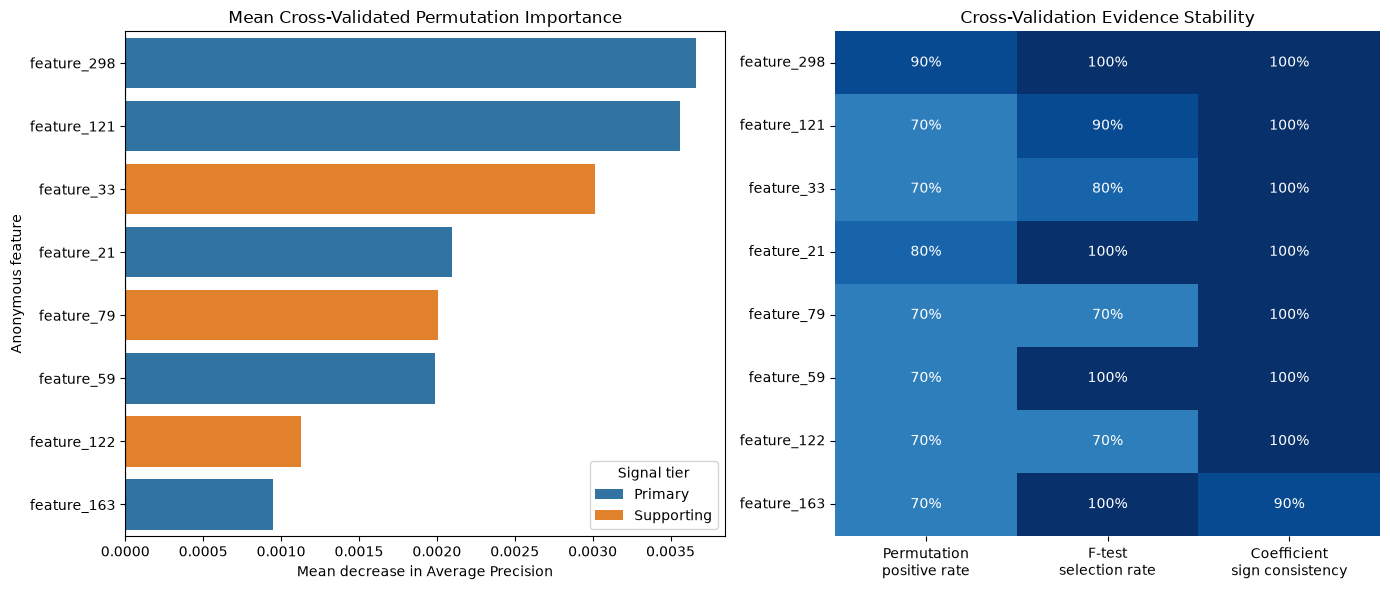

In [33]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6),
    gridspec_kw={
        "width_ratios": [1.1, 1]
    }
)

sns.barplot(
    data=plot_signal_table,
    y="feature",
    x="mean_importance",
    order=signal_order,
    hue="signal_tier",
    dodge=False,
    ax=axes[0]
)

axes[0].axvline(
    0,
    color="black",
    linewidth=0.8
)

axes[0].set_title(
    "Mean Cross-Validated Permutation Importance"
)

axes[0].set_xlabel(
    "Mean decrease in Average Precision"
)

axes[0].set_ylabel(
    "Anonymous feature"
)

axes[0].legend(
    title="Signal tier"
)

stability_matrix = (
    plot_signal_table
    .set_index("feature")
    .loc[
        signal_order,
        [
            "permutation_positive_rate",
            "f_test_selection_rate",
            "sign_consistency"
        ]
    ]
)

stability_matrix.columns = [
    "Permutation\npositive rate",
    "F-test\nselection rate",
    "Coefficient\nsign consistency"
]

sns.heatmap(
    stability_matrix,
    annot=True,
    fmt=".0%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    cbar=False,
    ax=axes[1]
)

axes[1].set_title(
    "Cross-Validation Evidence Stability"
)

axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [34]:
selected_signal_names = (
    primary_signals
    + supporting_signals
)

selected_measurements = (
    X[selected_signal_names].copy()
)

feature_medians = (
    selected_measurements.median()
)

feature_iqr = (
    selected_measurements.quantile(0.75)
    - selected_measurements.quantile(0.25)
)

feature_iqr = feature_iqr.replace(
    0,
    np.nan
)

robust_standardized = (
    selected_measurements
    - feature_medians
) / feature_iqr

distribution_long = (
    robust_standardized
    .assign(
        outcome=np.where(
            y == 1,
            "Fail",
            "Pass"
        )
    )
    .melt(
        id_vars="outcome",
        var_name="feature",
        value_name="robust_standardized_value"
    )
)

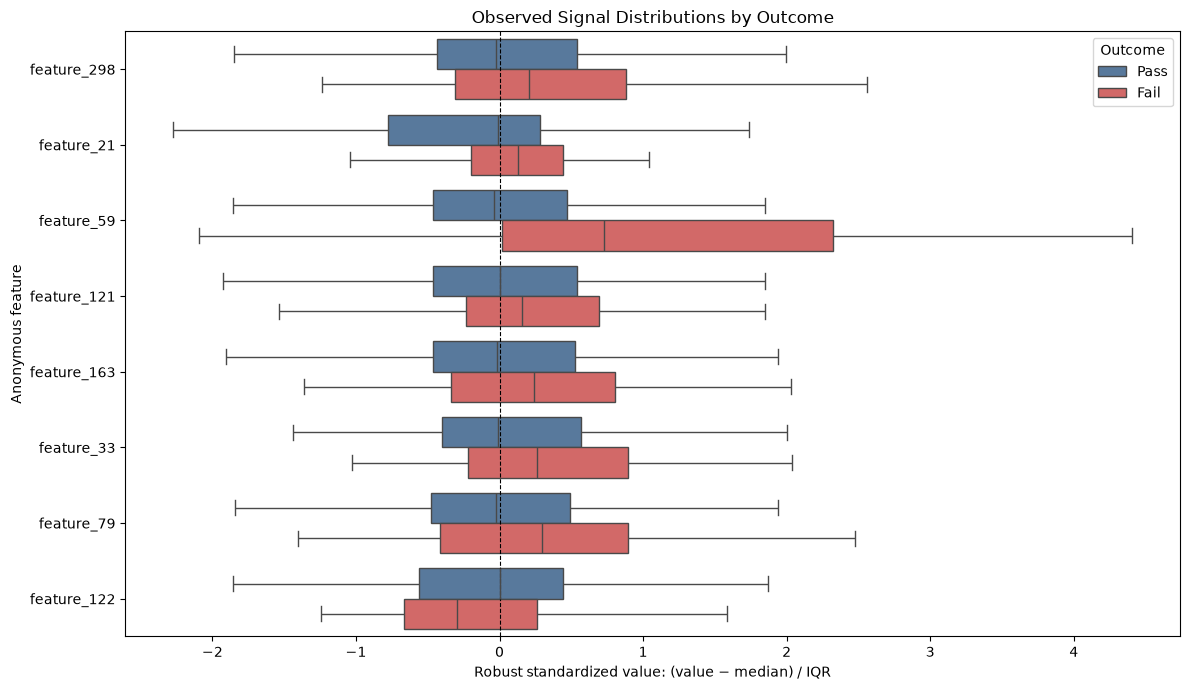

In [35]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=distribution_long,
    y="feature",
    x="robust_standardized_value",
    hue="outcome",
    order=selected_signal_names,
    showfliers=False,
    palette={
        "Pass": "#4C78A8",
        "Fail": "#E45756"
    }
)

plt.axvline(
    0,
    color="black",
    linewidth=0.8,
    linestyle="--"
)

plt.title(
    "Observed Signal Distributions by Outcome"
)

plt.xlabel(
    "Robust standardized value: (value − median) / IQR"
)

plt.ylabel(
    "Anonymous feature"
)

plt.legend(
    title="Outcome"
)

plt.tight_layout()
plt.show()

## 6.16 Missingness as a Potential Risk Signal

For each consensus signal, the missing-value rate is compared between Pass
and Fail samples.

Fisher's exact test is used because the Fail class is small and some
missing-value counts may also be small. Benjamini-Hochberg adjustment is
applied across the eight comparisons.

This is an exploratory association analysis. A difference in missingness
does not establish why a measurement was absent or whether missingness is
a physical cause of failure.

In [36]:
from scipy.stats import fisher_exact

missingness_rows = []

for feature in selected_signal_names:

    feature_missing = X[feature].isna()

    pass_missing = (
        feature_missing[y == 0].sum()
    )

    pass_observed = (
        (~feature_missing[y == 0]).sum()
    )

    fail_missing = (
        feature_missing[y == 1].sum()
    )

    fail_observed = (
        (~feature_missing[y == 1]).sum()
    )

    odds_ratio, p_value = fisher_exact([
        [fail_missing, fail_observed],
        [pass_missing, pass_observed]
    ])

    pass_missing_rate = (
        pass_missing
        / (pass_missing + pass_observed)
    )

    fail_missing_rate = (
        fail_missing
        / (fail_missing + fail_observed)
    )

    missingness_rows.append({
        "feature": feature,
        "pass_missing_count": pass_missing,
        "fail_missing_count": fail_missing,
        "pass_missing_rate": pass_missing_rate,
        "fail_missing_rate": fail_missing_rate,
        "missing_rate_difference": (
            fail_missing_rate
            - pass_missing_rate
        ),
        "missingness_odds_ratio": odds_ratio,
        "fisher_p_value": p_value
    })

missingness_summary = pd.DataFrame(
    missingness_rows
)

In [37]:
p_values = (
    missingness_summary[
        "fisher_p_value"
    ].to_numpy()
)

number_of_tests = len(p_values)

sort_order = np.argsort(
    p_values
)

sorted_p_values = p_values[
    sort_order
]

adjusted_sorted = (
    sorted_p_values
    * number_of_tests
    / np.arange(
        1,
        number_of_tests + 1
    )
)

adjusted_sorted = np.minimum.accumulate(
    adjusted_sorted[::-1]
)[::-1]

adjusted_sorted = np.minimum(
    adjusted_sorted,
    1
)

adjusted_p_values = np.empty(
    number_of_tests
)

adjusted_p_values[
    sort_order
] = adjusted_sorted

missingness_summary[
    "adjusted_p_value"
] = adjusted_p_values

missingness_summary = (
    missingness_summary
    .sort_values(
        "missing_rate_difference",
        key=np.abs,
        ascending=False
    )
)

missingness_summary.round({
    "pass_missing_rate": 3,
    "fail_missing_rate": 3,
    "missing_rate_difference": 3,
    "missingness_odds_ratio": 2,
    "fisher_p_value": 4,
    "adjusted_p_value": 4
})

,feature,pass_missing_count,fail_missing_count,pass_missing_rate,fail_missing_rate,missing_rate_difference,missingness_odds_ratio,fisher_p_value,adjusted_p_value
6,feature_79,24,0,0.016,0.00,-0.016,0.00,0.4000,0.8000
0,feature_298,1,1,0.001,0.01,0.009,14.19,0.1284,0.3423
1,feature_21,1,1,0.001,0.01,0.009,14.19,0.1284,0.3423
4,feature_163,1,1,0.001,0.01,0.009,14.19,0.1284,0.3423
3,feature_121,9,0,0.006,0.00,-0.006,0.00,1.0000,1.0000
7,feature_122,9,0,0.006,0.00,-0.006,0.00,1.0000,1.0000
2,feature_59,7,0,0.005,0.00,-0.005,0.00,1.0000,1.0000
5,feature_33,1,0,0.001,0.00,-0.001,0.00,1.0000,1.0000


In [38]:
direction_comparison_rows = []

for feature in selected_signal_names:

    pass_values = X.loc[
        y == 0,
        feature
    ].dropna()

    fail_values = X.loc[
        y == 1,
        feature
    ].dropna()

    pass_median = pass_values.median()
    fail_median = fail_values.median()

    pooled_iqr = (
        X[feature].quantile(0.75)
        - X[feature].quantile(0.25)
    )

    if pooled_iqr > 0:
        standardized_median_shift = (
            fail_median - pass_median
        ) / pooled_iqr
    else:
        standardized_median_shift = np.nan

    if standardized_median_shift > 0:
        descriptive_direction = "Positive"
    elif standardized_median_shift < 0:
        descriptive_direction = "Negative"
    else:
        descriptive_direction = "No median difference"

    logistic_direction = (
        final_signal_table
        .set_index("feature")
        .loc[
            feature,
            "dominant_direction"
        ]
    )

    direction_comparison_rows.append({
        "feature": feature,
        "pass_median": pass_median,
        "fail_median": fail_median,
        "standardized_median_shift": (
            standardized_median_shift
        ),
        "descriptive_direction": (
            descriptive_direction
        ),
        "logistic_direction": (
            logistic_direction
        ),
        "direction_agreement": (
            descriptive_direction
            == logistic_direction
        )
    })

direction_comparison = pd.DataFrame(
    direction_comparison_rows
)

direction_comparison.round({
    "pass_median": 3,
    "fail_median": 3,
    "standardized_median_shift": 3
})

,feature,pass_median,fail_median,standardized_median_shift,descriptive_direction,logistic_direction,direction_agreement
0,feature_298,0.052,0.059,0.228,Positive,Positive,True
1,feature_21,-5529.000,-5447.250,0.142,Positive,Positive,True
2,feature_59,0.722,5.522,0.767,Positive,Positive,True
3,feature_121,15.790,15.810,0.154,Positive,Positive,True
4,feature_163,0.119,0.135,0.254,Positive,Negative,False
5,feature_33,8.766,8.894,0.266,Positive,Positive,True
6,feature_79,0.000,0.008,0.319,Positive,Negative,False
7,feature_122,3.882,3.526,-0.300,Negative,Positive,False


## 6.17 Conclusions

Eight anonymous measurement variables satisfied the predefined consensus
criteria based on cross-validated permutation importance and repeated
F-test selection:

- feature_298
- feature_21
- feature_59
- feature_163
- feature_121
- feature_33
- feature_79
- feature_122

Among these variables, feature_298 showed the most balanced evidence. It
had the highest mean permutation importance, positive importance in nine
of ten validation folds, F-test selection in all ten training folds, and a
fully consistent positive Logistic Regression coefficient direction.

Feature_59 showed the largest mean F-statistic and the clearest observed
distributional separation between Pass and Fail samples. Its permutation
importance was positive in seven of ten folds, indicating that its
additional contribution to Random Forest risk ranking was less stable than
its univariate statistical association.

The observed Pass/Fail distributions and Logistic Regression coefficient
directions were broadly consistent for feature_298, feature_21,
feature_59, feature_121, and feature_33. Higher observed values of these
signals were generally associated with higher Fail risk.

Feature_163, feature_79, and feature_122 showed disagreement between their
univariate distributional direction and their multivariable Logistic
Regression coefficient direction. These variables remain predictive
candidates, but their direction should be treated as context-dependent
and should not be converted into simple high-value or low-value alarm
rules without further process knowledge.

Missing-value rates were low for all eight signals. None of the
missingness comparisons remained statistically significant after
multiple-testing adjustment. Missingness was therefore not identified as
a reliable independent risk indicator for these consensus signals.

Overall, the analysis identifies a compact set of stable anonymous
predictive signals for engineering investigation. These results provide
priorities for reviewing measurement definitions, process stages,
equipment associations, and temporal behavior. They do not establish
physical root causes or causal effects.